# 09 · Monte Carlo statistics and claims

> **In short:** a finite campaign can only bound the collision rate. This notebook explains the bounds used by the validation gates and applies them to the committed historical Stage 8 campaign.
>
> **Runtime:** a few seconds · **Read alongside:** [Claims and statistics](../2.Code/docs/validation/claims-and-statistics.md) · [Monte Carlo campaigns](../2.Code/docs/guides/monte-carlo.md)

**You will:**

- compare the one-sided Clopper–Pearson bound with the two-sided Wilson interval
- see how many trials a 0.10 collision gate needs
- summarize a campaign from its `trials.csv` with the package's statistics functions

In [1]:
from nbsetup import *

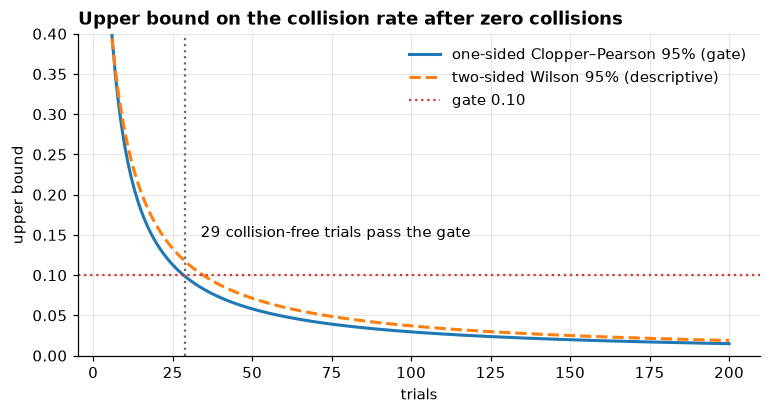

n=30: Clopper–Pearson 0.0950, Wilson 0.1135
n=50: Clopper–Pearson 0.0582, Wilson 0.0713


In [2]:
from quadrotor_mpc.application.validation.monte_carlo import (
    clopper_pearson_upper,
    mcnemar_exact,
    wilson_interval,
)

trials = np.arange(5, 201)
cp = [clopper_pearson_upper(0, n, 0.95) for n in trials]
wilson = [wilson_interval(0, n, 0.95)[1] for n in trials]
needed = trials[np.argmax(np.array(cp) <= 0.10)]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(trials, cp, lw=2, label="one-sided Clopper–Pearson 95% (gate)")
ax.plot(trials, wilson, lw=2, ls="--", label="two-sided Wilson 95% (descriptive)")
ax.axhline(0.10, color=CRITICAL, ls=":", label="gate 0.10")
ax.axvline(needed, color=NEUTRAL, ls=":")
ax.annotate(f"{needed} collision-free trials pass the gate", (needed, 0.10), xytext=(10, 25), textcoords="offset points")
ax.set(title="Upper bound on the collision rate after zero collisions", xlabel="trials", ylabel="upper bound",
       ylim=(0, 0.4))
ax.legend()
plt.show()
for n in (30, 50):
    print(f"n={n}: Clopper–Pearson {clopper_pearson_upper(0, n):.4f}, Wilson {wilson_interval(0, n)[1]:.4f}")

## The committed Stage 8 campaign (historical)

`2.Code/validation/stage8_30_seed/` holds 270 episodes run **before** the October 2026 corrections.
They are used here only to demonstrate the analysis; do not quote them for the current code.

In [3]:
import csv

campaign = CODE / "validation" / "stage8_30_seed"
rows = list(csv.DictReader((campaign / "trials.csv").open()))
truthy = lambda value: str(value).lower() in ("true", "1")
cells = {}
for row in rows:
    cells.setdefault((row["noise_label"], row["mode"]), []).append(row)

print(f"{'noise':14s} {'controller':14s} {'n':>3s} {'coll':>4s} {'CP upper':>8s} {'Wilson hi':>9s} "
      f"{'success':>7s} {'mean clear':>10s}")
for (noise, mode), items in cells.items():
    n = len(items)
    collisions = sum(truthy(r["collision"]) for r in items)
    success = sum(truthy(r["success"]) for r in items)
    clearance = np.mean([float(r["min_clearance_m"]) for r in items])
    print(f"{noise:14s} {mode:14s} {n:3d} {collisions:4d} {clopper_pearson_upper(collisions, n):8.4f} "
          f"{wilson_interval(collisions, n)[1]:9.4f} {success:4d}/{n} {clearance:10.3f}")

noise          controller       n coll CP upper Wilson hi success mean clear
quarter_sigma  deterministic   30    0   0.0950    0.1135   30/30      0.305
quarter_sigma  individual      30    0   0.0950    0.1135   30/30      0.326
quarter_sigma  joint           30    0   0.0950    0.1135   30/30      0.344
nominal_sigma  deterministic   30    0   0.0950    0.1135   30/30      0.314
nominal_sigma  individual      30    0   0.0950    0.1135   30/30      0.356
nominal_sigma  joint           30    0   0.0950    0.1135   30/30      0.414
four_sigma     deterministic   30    0   0.0950    0.1135   30/30      0.324
four_sigma     individual      30    0   0.0950    0.1135   30/30      0.467
four_sigma     joint           30    0   0.0950    0.1135    0/30      0.661


### Paired comparison

Each chance controller is compared with the deterministic one **on the same seeds**. Only discordant
seeds (one succeeds, the other fails) carry information; the exact McNemar test uses them.

quarter_sigma  individual     success: deterministic-only  0, individual-only  0, p = 1
quarter_sigma  joint          success: deterministic-only  0, joint-only  0, p = 1
nominal_sigma  individual     success: deterministic-only  0, individual-only  0, p = 1
nominal_sigma  joint          success: deterministic-only  0, joint-only  0, p = 1
four_sigma     individual     success: deterministic-only  0, individual-only  0, p = 1
four_sigma     joint          success: deterministic-only 30, joint-only  0, p = 1.86e-09


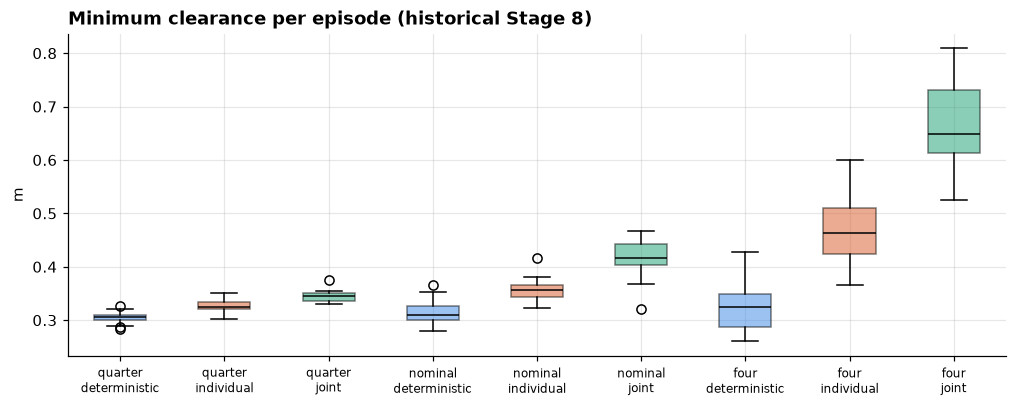

In [4]:
def paired(noise, mode, outcome="success"):
    baseline = {r["seed"]: truthy(r[outcome]) for r in cells[(noise, "deterministic")]}
    compared = {r["seed"]: truthy(r[outcome]) for r in cells[(noise, mode)]}
    baseline_only = sum(baseline[s] and not compared[s] for s in baseline)
    compared_only = sum(compared[s] and not baseline[s] for s in baseline)
    return mcnemar_exact(baseline_only, compared_only)

modes = sorted({mode for _, mode in cells if mode != "deterministic"})
for noise in dict.fromkeys(noise for noise, _ in cells):
    for mode in modes:
        result = paired(noise, mode)
        print(f"{noise:14s} {mode:14s} success: deterministic-only {result['baseline_only']:2d}, "
              f"{mode}-only {result['compared_only']:2d}, p = {result['p_value_exact_two_sided']:.3g}")

fig, ax = plt.subplots(figsize=(11, 3.8))
labels, data, colors = [], [], []
for (noise, mode), items in cells.items():
    labels.append(f"{noise.replace('_sigma', '')}\n{mode}")
    data.append([float(r["min_clearance_m"]) for r in items])
    colors.append(CONTROLLER_COLORS.get(mode if mode != "joint" else "joint_uniform", NEUTRAL))
box = ax.boxplot(data, patch_artist=True, medianprops={"color": "black"})
ax.set_xticks(range(1, len(labels) + 1), labels, fontsize=8)
for patch, color in zip(box["boxes"], colors):
    patch.set(facecolor=color, alpha=0.5)
ax.set(title="Minimum clearance per episode (historical Stage 8)", ylabel="m")
plt.show()

## Takeaways

- With zero collisions, 30 trials already pass a 0.10 gate under the one-sided Clopper–Pearson bound;
  the two-sided Wilson bound used by the old release did not.
- A passing gate yields `EMPIRICALLY_SUPPORTED_NOT_PROVEN`, never a proof.
- To produce current numbers run a campaign on a clean commit (workbench **Monte Carlo** page or
  `quadrotor-mpc-monte-carlo --config config/native_monte_carlo.yaml`) and point `campaign` above at its
  output folder.

---

**Previous:** [08_native_controller_comparison.ipynb](08_native_controller_comparison.ipynb)